In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LinearRegression, Lasso, LassoCV, Ridge, RidgeCV
from sklearn.metrics import mean_squared_error, r2_score, mean_absolute_error
import joblib

# Visualizations Style
sns.set_theme(style="whitegrid")
plt.rcParams['font.size'] = 10

In [2]:
# 2. Data Loading & Basic Inspection
df = pd.read_csv("data.csv")

print("Initial Dataset Shape:", df.shape)
print("Data Head:")
display(df.head())

print("\nData Info:")
df.info()

print("\nMissing Values:")
print(df.isnull().sum())

Initial Dataset Shape: (4600, 18)
Data Head:


,date,price,bedrooms,bathrooms,sqft_living,sqft_lot,floors,waterfront,view,condition,sqft_above,sqft_basement,yr_built,yr_renovated,street,city,statezip,country
0,2014-05-02 00:00:00,313000.0,3.0,1.50,1340,7912,1.5,0,0,3,1340,0,1955,2005,18810 Densmore Ave N,Shoreline,WA 98133,USA
1,2014-05-02 00:00:00,2384000.0,5.0,2.50,3650,9050,2.0,0,4,5,3370,280,1921,0,709 W Blaine St,Seattle,WA 98119,USA
2,2014-05-02 00:00:00,342000.0,3.0,2.00,1930,11947,1.0,0,0,4,1930,0,1966,0,26206-26214 143rd Ave SE,Kent,WA 98042,USA
3,2014-05-02 00:00:00,420000.0,3.0,2.25,2000,8030,1.0,0,0,4,1000,1000,1963,0,857 170th Pl NE,Bellevue,WA 98008,USA
4,2014-05-02 00:00:00,550000.0,4.0,2.50,1940,10500,1.0,0,0,4,1140,800,1976,1992,9105 170th Ave NE,Redmond,WA 98052,USA



Data Info:
<class 'pandas.DataFrame'>
RangeIndex: 4600 entries, 0 to 4599
Data columns (total 18 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   date           4600 non-null   str    
 1   price          4600 non-null   float64
 2   bedrooms       4600 non-null   float64
 3   bathrooms      4600 non-null   float64
 4   sqft_living    4600 non-null   int64  
 5   sqft_lot       4600 non-null   int64  
 6   floors         4600 non-null   float64
 7   waterfront     4600 non-null   int64  
 8   view           4600 non-null   int64  
 9   condition      4600 non-null   int64  
 10  sqft_above     4600 non-null   int64  
 11  sqft_basement  4600 non-null   int64  
 12  yr_built       4600 non-null   int64  
 13  yr_renovated   4600 non-null   int64  
 14  street         4600 non-null   str    
 15  city           4600 non-null   str    
 16  statezip       4600 non-null   str    
 17  country        4600 non-null   str    
dtypes: floa

In [3]:
# Feature Renaming
df = df.rename(columns={
    "sqft_lot": "Lot_square_feet",
    "sqft_living": "Living_square_feet",
    "sqft_basement": "Basement_square_feet",
    "yr_built": "Year_Built",
    "yr_renovated": "Year_Renovated"
})

# Date Processing
if 'date' in df.columns:
    df['date'] = pd.to_datetime(df['date'])
    df['Sale_year'] = df['date'].dt.year
    df['Sale_month'] = df['date'].dt.month
    df['Sale_day'] = df['date'].dt.day
    df = df.drop(columns=['date'])

# Location Processing (statezip)
if 'statezip' in df.columns:
    df['State_Name'] = df['statezip'].astype(str).str.split(' ').str[0]
    df['Zip_Code'] = df['statezip'].astype(str).str.split(' ').str[1]
    df = df.drop(columns=['statezip'])

# Drop Unnecessary  Columns
columns_to_drop = [col for col in ['country', 'street'] if col in df.columns]
if columns_to_drop:
    df = df.drop(columns=columns_to_drop)

print("Cleaned Data Head:")
display(df.head())

Cleaned Data Head:


,price,bedrooms,bathrooms,Living_square_feet,Lot_square_feet,floors,waterfront,view,condition,sqft_above,Basement_square_feet,Year_Built,Year_Renovated,city,Sale_year,Sale_month,Sale_day,State_Name,Zip_Code
0,313000.0,3.0,1.50,1340,7912,1.5,0,0,3,1340,0,1955,2005,Shoreline,2014,5,2,WA,98133
1,2384000.0,5.0,2.50,3650,9050,2.0,0,4,5,3370,280,1921,0,Seattle,2014,5,2,WA,98119
2,342000.0,3.0,2.00,1930,11947,1.0,0,0,4,1930,0,1966,0,Kent,2014,5,2,WA,98042
3,420000.0,3.0,2.25,2000,8030,1.0,0,0,4,1000,1000,1963,0,Bellevue,2014,5,2,WA,98008
4,550000.0,4.0,2.50,1940,10500,1.0,0,0,4,1140,800,1976,1992,Redmond,2014,5,2,WA,98052


In [4]:
# 4. Outliers Removal using IQR Method
def remove_outliers_iqr(dataframe, cols):
    df_clean = dataframe.copy()
    initial_shape = df_clean.shape[0]
    
    for col in cols:
        if col in df_clean.columns:
            Q1 = df_clean[col].quantile(0.25)
            Q3 = df_clean[col].quantile(0.75)
            IQR = Q3 - Q1
            
            lower_bound = Q1 - 1.5 * IQR
            upper_bound = Q3 + 1.5 * IQR
            
            df_clean = df_clean[(df_clean[col] >= lower_bound) & (df_clean[col] <= upper_bound)]
    
    final_shape = df_clean.shape[0]
    print(f"Total Outlier Rows Removed: {initial_shape - final_shape}")
    print(f"Remaining Cleaned Dataset Rows: {final_shape}")
    return df_clean

# Main numerical features par outlier filtering apply karein
df = remove_outliers_iqr(df, ['price', 'Living_square_feet', 'Lot_square_feet'])

Total Outlier Rows Removed: 802
Remaining Cleaned Dataset Rows: 3798


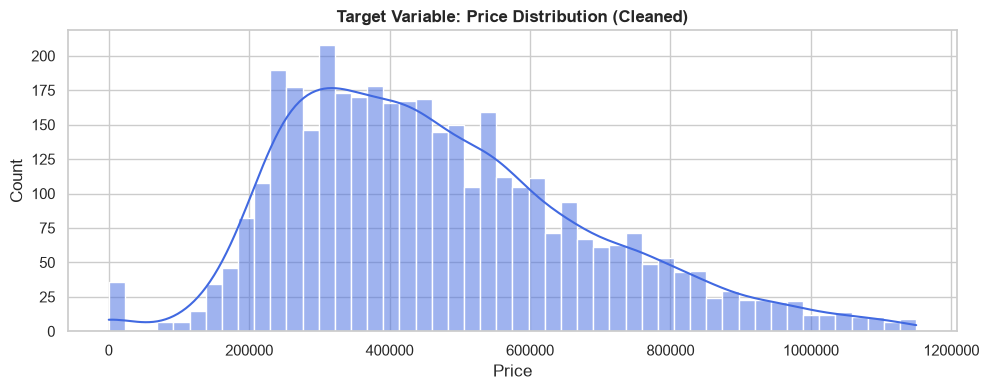

C:\Users\admin\AppData\Local\Temp\ipykernel_16288\872535230.py:21: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=df, x='bedrooms', y='price', ax=axes[1], palette='Blues')
C:\Users\admin\AppData\Local\Temp\ipykernel_16288\872535230.py:26: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=df, x='bathrooms', y='price', ax=axes[2], palette='Greens')


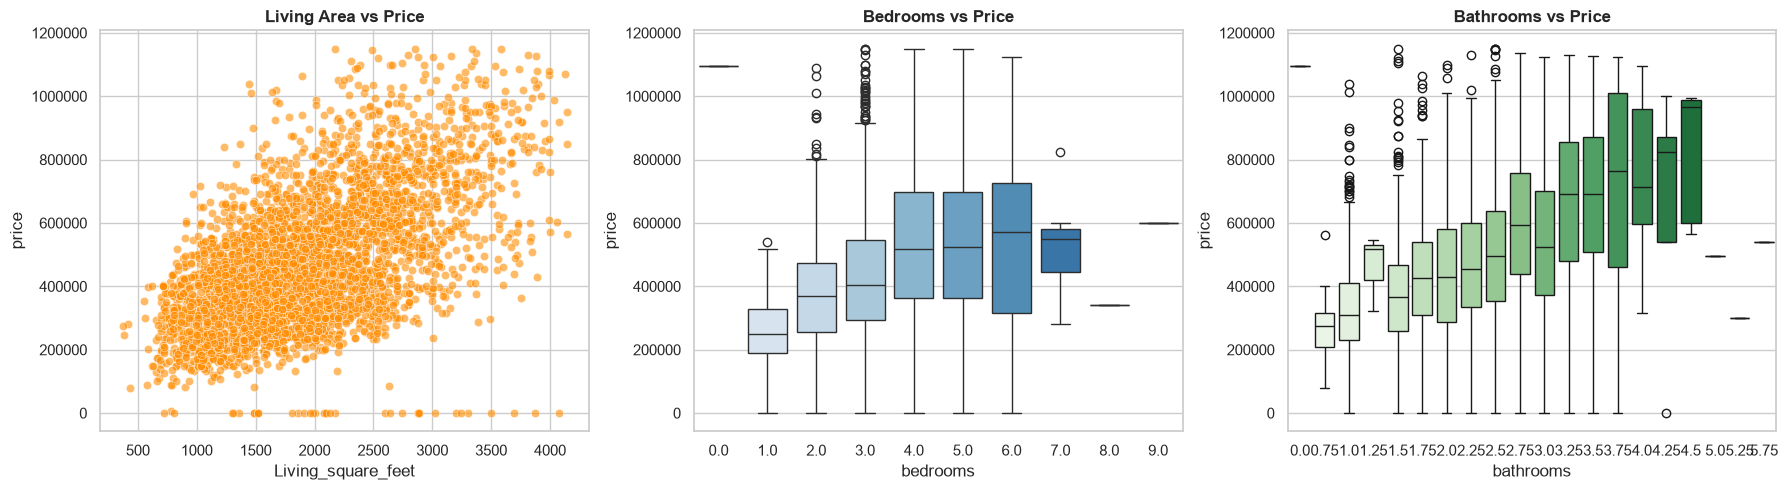

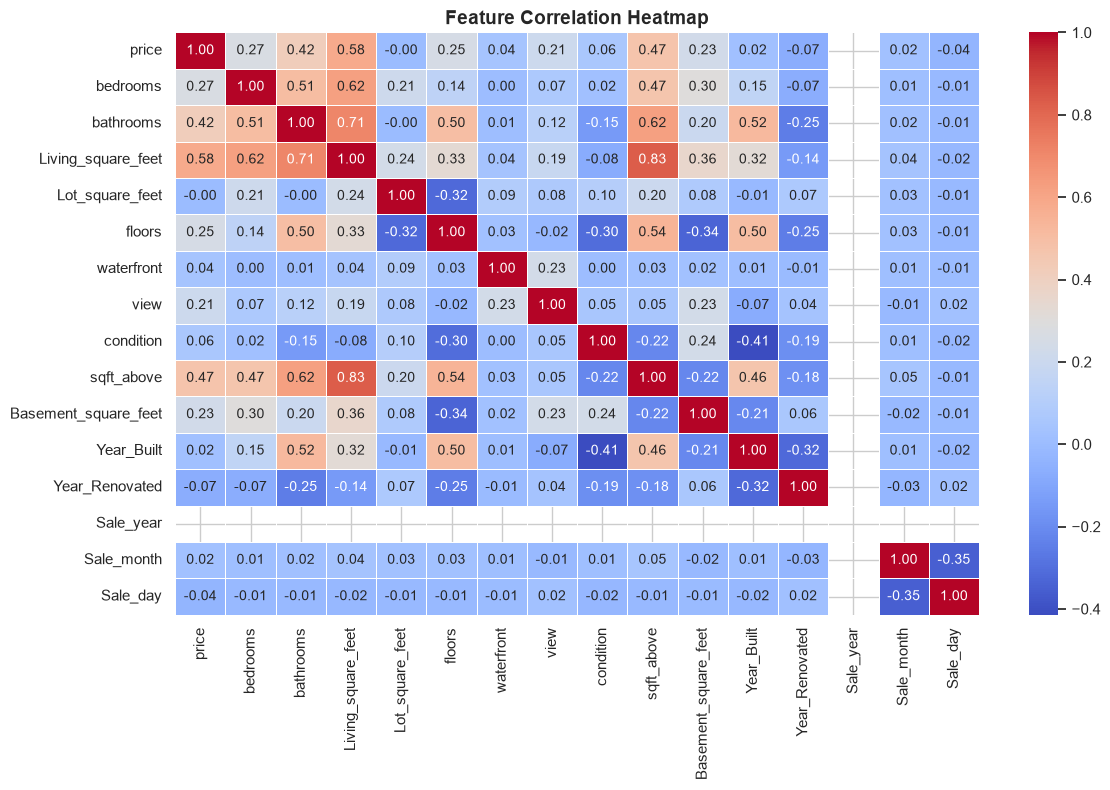

C:\Users\admin\AppData\Local\Temp\ipykernel_16288\872535230.py:45: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=top_cities.values, y=top_cities.index, palette='magma')


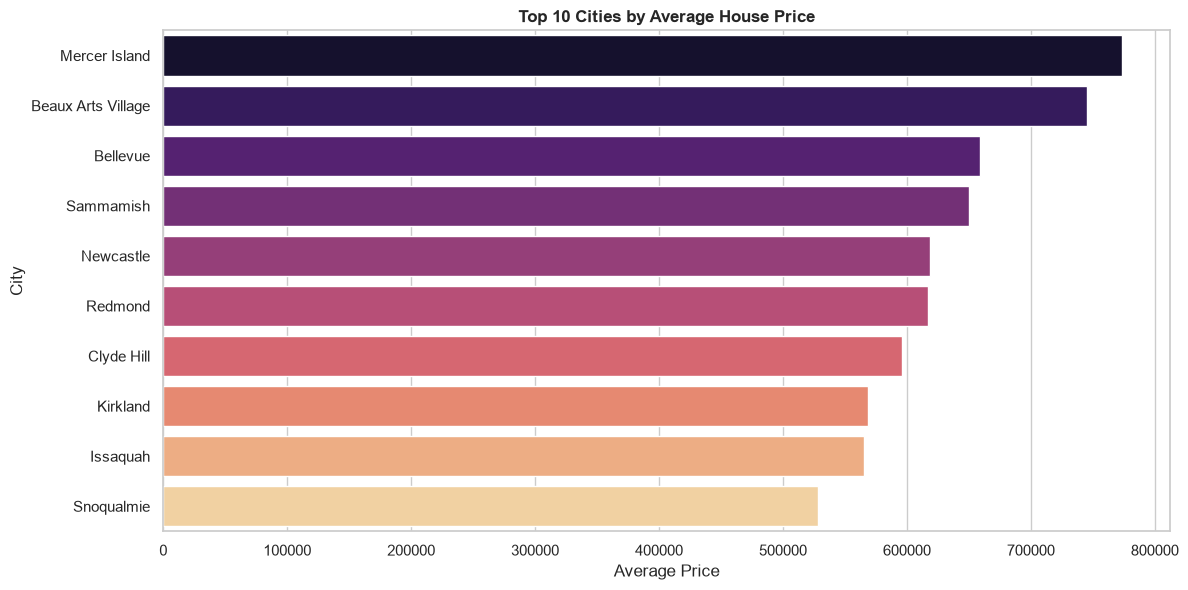

In [5]:
# 5. Exploratory Data Analysis (EDA) Visualizations

# Plot 1: Target Variable (Price Distribution after Outliers Removal)
plt.figure(figsize=(10, 4))
sns.histplot(df['price'], kde=True, bins=50, color='royalblue')
plt.title('Target Variable: Price Distribution (Cleaned)', fontsize=12, fontweight='bold')
plt.xlabel('Price')
plt.ylabel('Count')
plt.ticklabel_format(style='plain', axis='x')
plt.tight_layout()
plt.show()

# Plot 2: Key Features vs Price
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

sns.scatterplot(data=df, x='Living_square_feet', y='price', ax=axes[0], alpha=0.6, color='darkorange')
axes[0].set_title('Living Area vs Price', fontweight='bold')
axes[0].ticklabel_format(style='plain', axis='y')

if 'bedrooms' in df.columns:
    sns.boxplot(data=df, x='bedrooms', y='price', ax=axes[1], palette='Blues')
    axes[1].set_title('Bedrooms vs Price', fontweight='bold')
    axes[1].ticklabel_format(style='plain', axis='y')

if 'bathrooms' in df.columns:
    sns.boxplot(data=df, x='bathrooms', y='price', ax=axes[2], palette='Greens')
    axes[2].set_title('Bathrooms vs Price', fontweight='bold')
    axes[2].ticklabel_format(style='plain', axis='y')

plt.tight_layout()
plt.show()

# Plot 3: Feature Correlation Heatmap
plt.figure(figsize=(12, 8))
numeric_df = df.select_dtypes(include=['float64', 'int64', 'int32'])
sns.heatmap(numeric_df.corr(), annot=True, fmt=".2f", cmap="coolwarm", linewidths=0.5)
plt.title('Feature Correlation Heatmap', fontsize=14, fontweight='bold')
plt.tight_layout()
plt.show()

# Plot 4: Top 10 Cities by Average House Price
if 'city' in df.columns:
    plt.figure(figsize=(12, 6))
    top_cities = df.groupby('city')['price'].mean().sort_values(ascending=False).head(10)
    sns.barplot(x=top_cities.values, y=top_cities.index, palette='magma')
    plt.title('Top 10 Cities by Average House Price', fontsize=12, fontweight='bold')
    plt.xlabel('Average Price')
    plt.ylabel('City')
    plt.ticklabel_format(style='plain', axis='x')
    plt.tight_layout()
    plt.show()

In [6]:
df_encoded = pd.get_dummies(df, drop_first=True)

X = df_encoded.drop(columns=['price'])
y = df_encoded['price']

# Train-Test Split
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

print(f"X_train shape: {X_train.shape}, X_test shape: {X_test.shape}")

X_train shape: (3038, 132), X_test shape: (760, 132)


In [7]:
model = LinearRegression()
model.fit(X_train_scaled, y_train)
y_pred = model.predict(X_test_scaled)

lasso_cv = LassoCV(alphas=np.logspace(-3, 3, 1000), cv=5, random_state=42)
lasso_cv.fit(X_train_scaled, y_train)
best_lasso_alpha = lasso_cv.alpha_

lasso = Lasso(alpha=best_lasso_alpha, random_state=42)
lasso.fit(X_train_scaled, y_train)
y_pred_lasso = lasso.predict(X_test_scaled)

ridge_cv = RidgeCV(alphas=np.logspace(-3, 3, 100), cv=5)
ridge_cv.fit(X_train_scaled, y_train)
best_ridge_alpha = ridge_cv.alpha_

ridge = Ridge(alpha=best_ridge_alpha, random_state=42)
ridge.fit(X_train_scaled, y_train)
y_pred_ridge = ridge.predict(X_test_scaled)

results_df = pd.DataFrame({
    'Model': ['Linear Regression', 'Lasso Regression', 'Ridge Regression'],
    'Best Alpha': ['N/A', round(best_lasso_alpha, 4), round(best_ridge_alpha, 4)],
    'R2 Score': [r2_score(y_test, y_pred), r2_score(y_test, y_pred_lasso), r2_score(y_test, y_pred_ridge)],
    'MAE': [mean_absolute_error(y_test, y_pred), mean_absolute_error(y_test, y_pred_lasso), mean_absolute_error(y_test, y_pred_ridge)],
    'RMSE': [np.sqrt(mean_squared_error(y_test, y_pred)), np.sqrt(mean_squared_error(y_test, y_pred_lasso)), np.sqrt(mean_squared_error(y_test, y_pred_ridge))]
})

print("=== Model Performance Comparison ===")
display(results_df)

=== Model Performance Comparison ===


,Model,Best Alpha,R2 Score,MAE,RMSE
0,Linear Regression,N/A,0.711851,72407.325376,115067.456465
1,Lasso Regression,959.3608,0.712688,72613.849416,114900.289710
2,Ridge Regression,123.2847,0.710662,72798.114256,115304.746748


In [8]:
joblib.dump(ridge, 'best_ridge_model.pkl')
joblib.dump(lasso, 'best_lasso_model.pkl')
joblib.dump(scaler, 'scaler.pkl')
joblib.dump(list(X.columns), 'model_columns.pkl')
print("Model columns saved successfully!")
print("Models and Scaler successfully saved using joblib!")

loaded_model = joblib.load('best_ridge_model.pkl')
loaded_scaler = joblib.load('scaler.pkl')

sample_pred = loaded_model.predict(loaded_scaler.transform(X_test.iloc[:1]))
print(f"Sample Prediction from Saved Model: {sample_pred[0]:,.2f}")

Model columns saved successfully!
Models and Scaler successfully saved using joblib!
Sample Prediction from Saved Model: 551,345.05


In [9]:
joblib.dump(ridge, 'best_ridge_model.pkl')
joblib.dump(scaler, 'scaler.pkl')
joblib.dump(list(X.columns), 'model_columns.pkl')

print("Teenon .pkl files successfully save ho gayi hain!")

Teenon .pkl files successfully save ho gayi hain!


In [10]:
joblib.dump(scaler, 'scaler.pkl')
joblib.dump(list(X.columns), 'model_columns.pkl')

print("scaler.pkl aur model_columns.pkl successfully save ho gayi hain!")

scaler.pkl aur model_columns.pkl successfully save ho gayi hain!
